In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

os.makedirs('images', exist_ok=True)
print("All imports successful!")

All imports successful!


In [9]:
df = pd.read_csv('/mnt/software_requirements_cleaned.csv')

# Type column has values like 'F', 'US', 'PE', 'LF' etc.
# 'F' = Functional | everything else = Non-Functional
df['is_functional'] = (df['Type'] == 'F').astype(int)

X = df[['requirement_length', 'requirement_length_scaled']]
y = df['is_functional']

print("Class distribution:")
print(y.value_counts())
print("\n0 = Non-Functional (329), 1 = Functional (198)")
print("Shape:", df.shape)

Class distribution:
is_functional
0    329
1    198
Name: count, dtype: int64

0 = Non-Functional (329), 1 = Functional (198)
Shape: (527, 6)


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train size:", len(X_train))
print("Test size: ", len(X_test))

Train size: 421
Test size:  106


In [11]:
# No depth limit = tree memorises training data = overfitting
dt_full = DecisionTreeClassifier(random_state=42)
dt_full.fit(X_train, y_train)

train_acc = accuracy_score(y_train, dt_full.predict(X_train))
test_acc  = accuracy_score(y_test,  dt_full.predict(X_test))

print(f"Train Accuracy: {train_acc:.4f}")
print(f"Test Accuracy : {test_acc:.4f}")
print()
print("Train >> Test means the tree memorised training data (overfitting).")

Train Accuracy: 0.7411
Test Accuracy : 0.5755

Train >> Test means the tree memorised training data (overfitting).


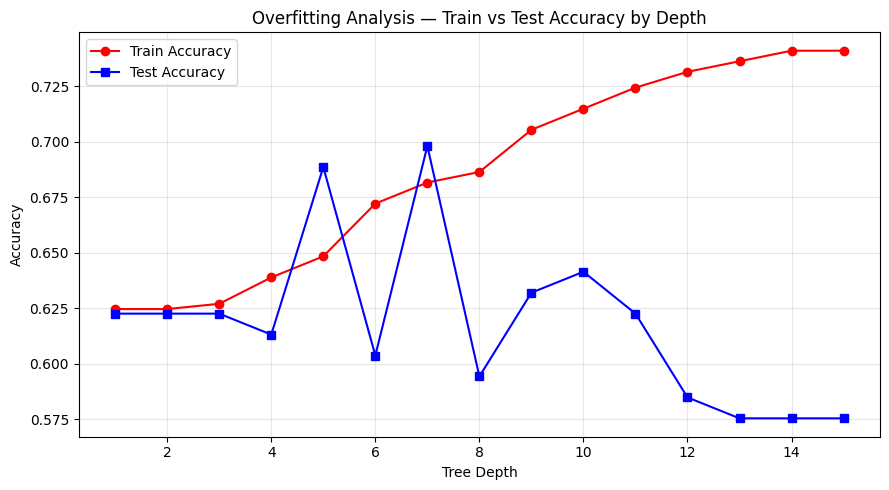

In [12]:
depths = range(1, 16)
train_accs = []
test_accs  = []

for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, random_state=42)
    dt.fit(X_train, y_train)
    train_accs.append(accuracy_score(y_train, dt.predict(X_train)))
    test_accs.append(accuracy_score(y_test,  dt.predict(X_test)))

plt.figure(figsize=(9, 5))
plt.plot(depths, train_accs, 'o-', color='red',  label='Train Accuracy')
plt.plot(depths, test_accs,  's-', color='blue', label='Test Accuracy')
plt.xlabel('Tree Depth')
plt.ylabel('Accuracy')
plt.title('Overfitting Analysis — Train vs Test Accuracy by Depth')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('images/overfitting_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

In [13]:
# Auto-detect the best depth — don't hardcode it
best_depth = list(depths)[test_accs.index(max(test_accs))]
print(f"Best depth: {best_depth}  |  Test Accuracy: {max(test_accs):.4f}")

dt_best = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
dt_best.fit(X_train, y_train)

y_pred = dt_best.predict(X_test)

print(f"\nTrain Accuracy: {accuracy_score(y_train, dt_best.predict(X_train)):.4f}")
print(f"Test Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print()
print(classification_report(y_test, y_pred, target_names=['Non-Functional', 'Functional']))

Best depth: 7  |  Test Accuracy: 0.6981

Train Accuracy: 0.6817
Test Accuracy : 0.6981

                precision    recall  f1-score   support

Non-Functional       0.75      0.77      0.76        66
    Functional       0.61      0.57      0.59        40

      accuracy                           0.70       106
     macro avg       0.68      0.67      0.68       106
  weighted avg       0.70      0.70      0.70       106



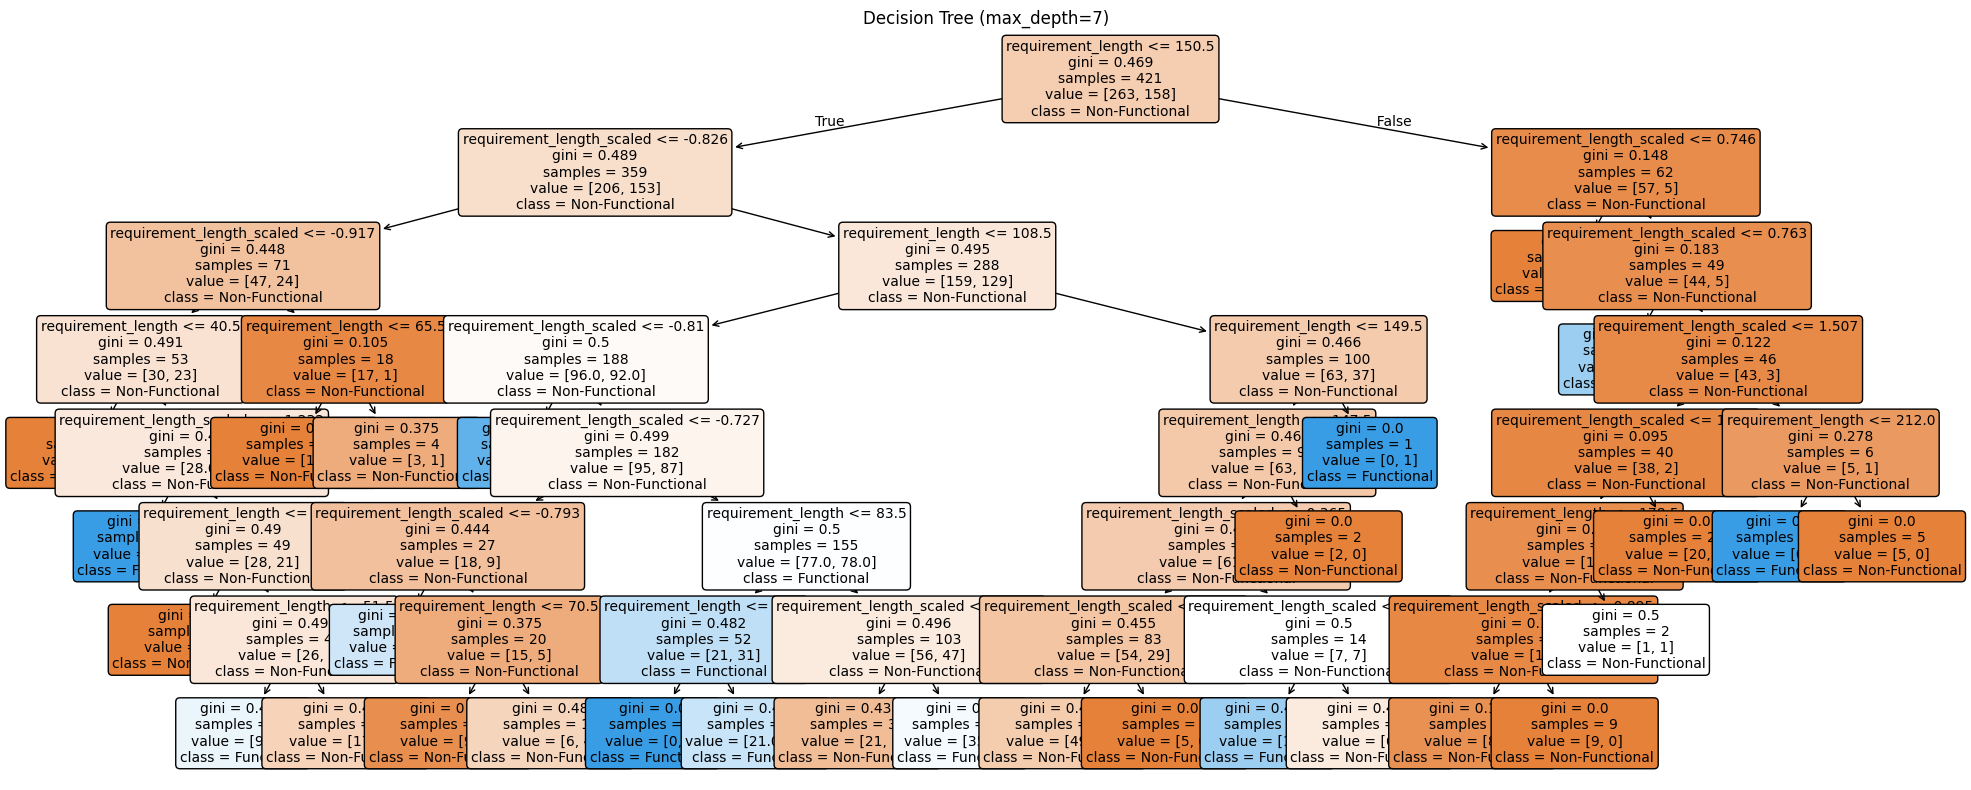

In [14]:
plt.figure(figsize=(20, 8))
plot_tree(
    dt_best,
    feature_names=['requirement_length', 'requirement_length_scaled'],
    class_names=['Non-Functional', 'Functional'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title(f'Decision Tree (max_depth={best_depth})')
plt.tight_layout()
plt.savefig('images/decision_tree_viz.png', dpi=150, bbox_inches='tight')
plt.show()

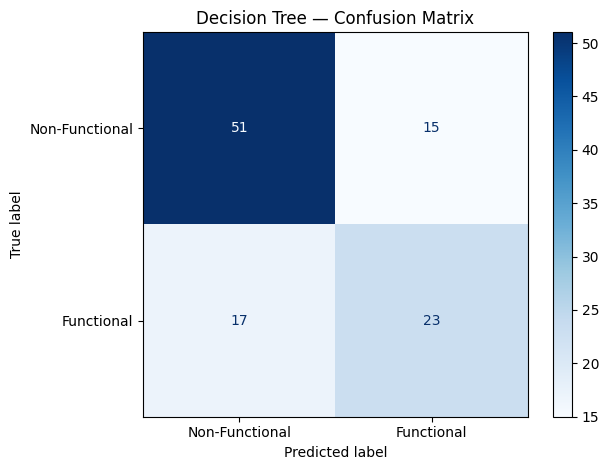

In [15]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=['Non-Functional', 'Functional'])
disp.plot(cmap='Blues')
plt.title('Decision Tree — Confusion Matrix')
plt.tight_layout()
plt.savefig('images/dt_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

In [16]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print(f"Train Accuracy: {accuracy_score(y_train, rf.predict(X_train)):.4f}")
print(f"Test Accuracy : {accuracy_score(y_test, y_pred_rf):.4f}")
print()
print(classification_report(y_test, y_pred_rf, target_names=['Non-Functional', 'Functional']))

Train Accuracy: 0.7411
Test Accuracy : 0.6038

                precision    recall  f1-score   support

Non-Functional       0.66      0.76      0.70        66
    Functional       0.47      0.35      0.40        40

      accuracy                           0.60       106
     macro avg       0.56      0.55      0.55       106
  weighted avg       0.59      0.60      0.59       106



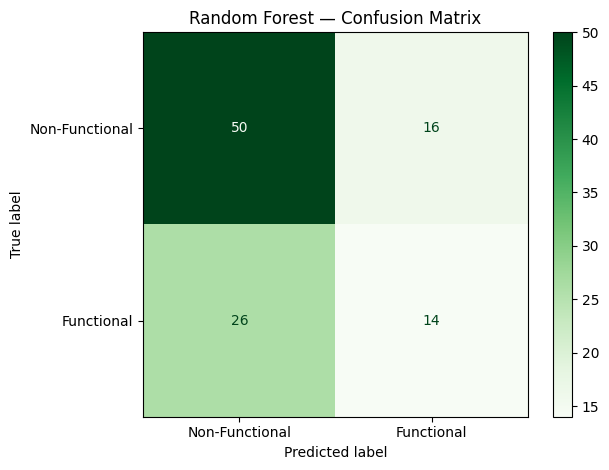

In [17]:
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp_rf = ConfusionMatrixDisplay(cm_rf, display_labels=['Non-Functional', 'Functional'])
disp_rf.plot(cmap='Greens')
plt.title('Random Forest — Confusion Matrix')
plt.tight_layout()
plt.savefig('images/rf_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

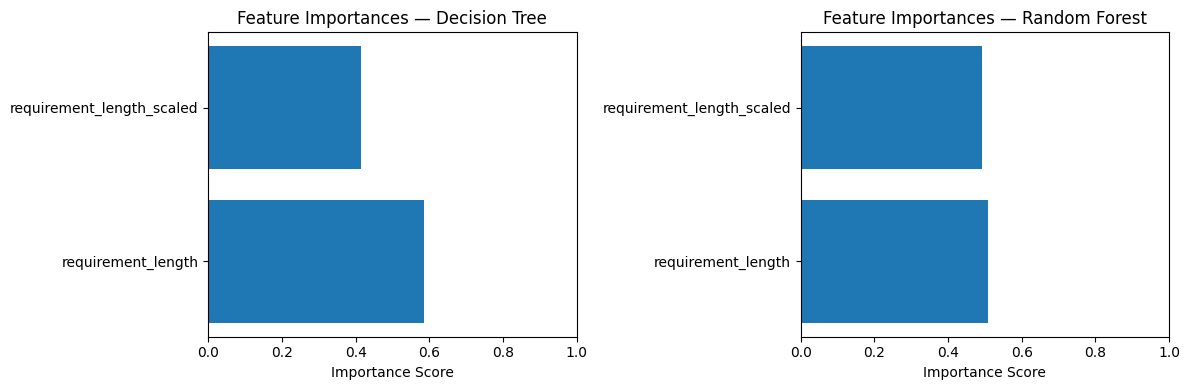

In [18]:
feat_names = ['requirement_length', 'requirement_length_scaled']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, model, title in zip(axes,
                              [dt_best, rf],
                              ['Decision Tree', 'Random Forest']):
    ax.barh(feat_names, model.feature_importances_)
    ax.set_xlim(0, 1)
    ax.set_title(f'Feature Importances — {title}')
    ax.set_xlabel('Importance Score')

plt.tight_layout()
plt.savefig('images/feature_importances.png', dpi=150, bbox_inches='tight')
plt.show()

Decision Tree CV: 0.5635 ± 0.0321
Random Forest CV: 0.5427 ± 0.0373


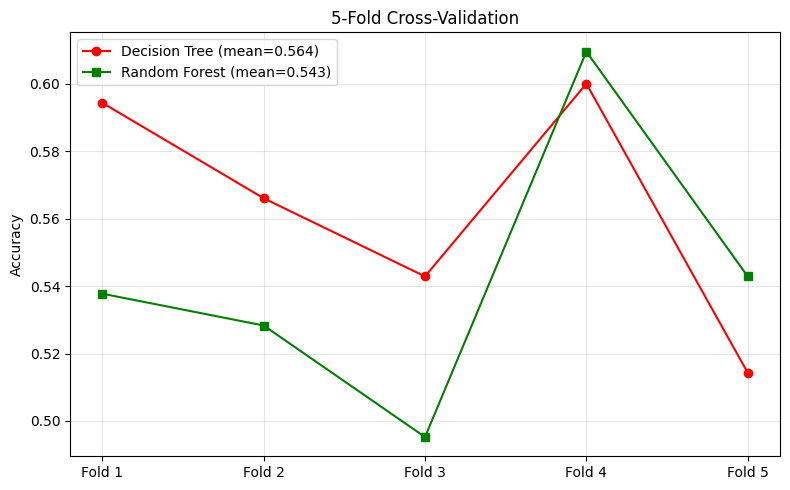

In [19]:
# cross_val_score refits the model on each fold internally
# so passing the full X, y here is correct
cv_dt = cross_val_score(dt_best, X, y, cv=5, scoring='accuracy')
cv_rf = cross_val_score(rf,      X, y, cv=5, scoring='accuracy')

print(f"Decision Tree CV: {cv_dt.mean():.4f} ± {cv_dt.std():.4f}")
print(f"Random Forest CV: {cv_rf.mean():.4f} ± {cv_rf.std():.4f}")

plt.figure(figsize=(8, 5))
plt.plot(range(1, 6), cv_dt, 'o-', color='red',   label=f'Decision Tree (mean={cv_dt.mean():.3f})')
plt.plot(range(1, 6), cv_rf, 's-', color='green',  label=f'Random Forest (mean={cv_rf.mean():.3f})')
plt.xticks(range(1, 6), [f'Fold {i}' for i in range(1, 6)])
plt.ylabel('Accuracy')
plt.title('5-Fold Cross-Validation')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('images/cross_validation.png', dpi=150, bbox_inches='tight')
plt.show()

In [20]:
results = {
    'Model': ['DT Full (overfit)', f'DT depth={best_depth}', 'Random Forest'],
    'Test Accuracy': [
        round(accuracy_score(y_test, dt_full.predict(X_test)), 4),
        round(accuracy_score(y_test, y_pred), 4),
        round(accuracy_score(y_test, y_pred_rf), 4)
    ],
    'CV Mean': ['-', f'{cv_dt.mean():.4f}', f'{cv_rf.mean():.4f}']
}

print(pd.DataFrame(results).to_string(index=False))

            Model  Test Accuracy CV Mean
DT Full (overfit)         0.5755       -
       DT depth=7         0.6981  0.5635
    Random Forest         0.6038  0.5427
